# Eole による英日ニューラル機械翻訳演習

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch4_eole.ipynb)

書籍 第4章 4-4「演習：機械翻訳」に対応します。田中コーパスで学習し、開発データの BLEU でチェックポイントを選び、テストデータの訳を評価します。

Eole というツールを用いて英日機械翻訳の演習を行います。Eole は、書籍で紹介している OpenNMT-py の後継のツールです。OpenNMT-py は2024年の v3.5.1 で開発が止まっているため、この演習では Eole を使います。コマンド名や設定ファイルの書き方は少し違いますが、できることはほぼ同じです。
Google Colaboratory は GPU を用いた実験ができるので、GPU を用いてニューラル機械翻訳の実験をしましょう。（「ランタイム」→「ランタイムのタイプを変更」から「ハードウェア アクセラレータ」を GPU（T4 など）にしておいてください。以下、Python 3 で説明します。）
データは田中コーパスという自由に使える対訳コーパスを使用します。翻訳結果を実際に見て評価する、ということも演習の目的です。

In [1]:
import torch

if torch.cuda.is_available():
    print(f"GPU が利用可能です: {torch.cuda.get_device_name(0)}")
else:
    print(
        "警告: GPU が検出されませんでした（現在 CPU モードです）。\n"
        "「ランタイム」→「ランタイムのタイプを変更」から「ハードウェア アクセラレータ」を GPU（T4 など）に変更してください。"
    )

GPU が利用可能です: Tesla T4


## Eole のインストール

### pip によるインストール
Eole を使って実験を行います。開発が速く、数週間で内容が変わってしまうことがあるので、ここでは2026年10月時点の最新版である v0.6.4 というバージョンを使います。pip というのは Python のソフトウェアをインストールするときに使うツールの名前で、依存関係も含めて自動でセットアップしてくれます。

ただし、2026年10月時点の Google Colab の Python は 3.13 ですが、Eole が使うライブラリ（pyonmttok や fasttext）は Python 3.12 までしか対応していないため、そのままでは `pip install eole` が失敗します。そこで、[uv](https://docs.astral.sh/uv/) という高速なパッケージ管理ツールを使って Python 3.12 の仮想環境を /content/eole-env に作り、そこに Eole と PyTorch をインストールします。1〜2分かかります。最後に `True` と表示されれば GPU が使えます。

In [2]:
!pip install -q uv
!uv venv -q --clear -p 3.12 /content/eole-env
# eole 0.6.4 の CLI（eole.bin.tools.load_test）が aiohttp をインポートするため明示的に追加
!uv pip install -q -p /content/eole-env eole==0.6.4 aiohttp
!/content/eole-env/bin/python -c "import sys, torch; print(sys.version, torch.__version__, torch.cuda.is_available())"

3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0] 2.14.1+cu130 True


以下では `!eole ...` のようにコマンドを実行するので、作った仮想環境のコマンドが使えるように PATH を設定しておきます。ランタイムを再起動した場合は、このセルをもう一度実行してください。

In [3]:
import os
os.environ["PATH"] = "/content/eole-env/bin:" + os.environ["PATH"]
!which eole

/content/eole-env/bin/eole


## 対訳データのインストールと前処理

### 田中コーパス
田中コーパスというデータで翻訳実験を行います。日本の大学生が翻訳したデータです。そのうち適当な長さの5万文だけを抽出して実験しやすいようにしてくれたデータを用います。
train.{ja,en}というのが学習データ、dev.{ja,en}というのが開発データ、test.{ja,en}というのがテストデータです。

In [4]:
![ -d small_parallel_enja ] || git clone https://github.com/odashi/small_parallel_enja

Cloning into 'small_parallel_enja'...
Resolving deltas: 100% (18/18), done.


In [5]:
!ls small_parallel_enja

dev.en	   train.en.000       train.en.vocab.all  train.ja.004
dev.ja	   train.en.001       train.ja		  train.ja.vocab.4k
README.md  train.en.002       train.ja.000	  train.ja.vocab.all
test.en    train.en.003       train.ja.001
test.ja    train.en.004       train.ja.002
train.en   train.en.vocab.4k  train.ja.003


### データの前処理
`eole build_vocab` というコマンドでデータの前処理をします。語彙のサイズをコントロールしたり、単語分割をしたりします。YAML という形式で書かれた設定ファイルが必要なので、準備しておきます。以下では tanaka-enja.yaml という名前で設定ファイルを保存します。
Eole の設定ファイルでは、モデルの設定を `model:`、学習の設定を `training:` の下にまとめて書きます。

In [6]:
%%bash
cat > tanaka-enja.yaml << __EOF__
# 前処理したデータの出力先の設定
save_data: ./tanaka
src_vocab: ./tanaka/vocab.src
tgt_vocab: ./tanaka/vocab.tgt
overwrite: True

# 学習に必要なデータが置いてある置き場所
data:
    corpus_1:
        path_src: small_parallel_enja/train.en
        path_tgt: small_parallel_enja/train.ja
    valid:
        path_src: small_parallel_enja/dev.en
        path_tgt: small_parallel_enja/dev.ja

# モデルの設定（RNN (LSTM) を使う）
model:
    architecture: rnn

# ここから学習時の設定
training:
    world_size: 1
    gpu_ranks: [0]
    model_path: ./tanaka/run/model
    save_checkpoint_steps: 500
    train_steps: 20000
    valid_steps: 500
__EOF__

In [7]:
!eole build_vocab -c tanaka-enja.yaml -n_sample 10000

[2026-11-19 02:17:43,785 INFO] Transforms applied: []
[2026-11-19 02:17:43,786 INFO] Counter vocab from 10000 samples.
[2026-11-19 02:17:43,786 INFO] Build vocab on 10000 transformed examples/corpus.
[2026-11-19 02:17:43,918 INFO] Counters src: 3447
[2026-11-19 02:17:43,918 INFO] Counters tgt: 4181


## NMTの訓練

### 学習
`eole train` というコマンドで学習します。上述の設定ファイルで挙動を制御できます。いくつかオプションがあるので、変えてみると挙動も変わります。
world_size で使う GPU の個数、gpu_ranks で使う GPU を指定します（0スタートです）。指定しないと CPU になってしまいます。CPU は GPU の数十倍遅いです。
train_steps は学習するステップを指定します。20,000だとこのデータは T4 GPU で30分弱で学習できます（500ステップごとの検証を含みます）。

デフォルトでは `tanaka-enja.yaml`（`architecture: rnn` の RNN (LSTM)）を使って学習します。Transformer を試したい場合、RNN のデフォルト設定（SGD や文単位バッチ）のまま `architecture: transformer` だけを変更すると学習が収束しないため、`optim: adam`、`decay_method: noam`、`warmup_steps: 4000`、トークン単位バッチ (`batch_type: tokens`)、`label_smoothing: 0.1` などの設定を合わせて指定する必要があります。下のセルでは Transformer 用の設定ファイル `tanaka-enja-transformer.yaml` も生成しており、`USE_TRANSFORMER = True` に切り替えるだけで試せます。その他の設定は[設定ファイルの書き方](https://eole-nlp.github.io/eole/docs/concepts/config)や[モデルの設定一覧](https://eole-nlp.github.io/eole/docs/reference/Config/models)を見て編集してみましょう。（ただし、今回はデータが少ないので Transformer で学習しても必ずしも RNN より精度が高くなるとは限りません）

In [8]:
import os
from pathlib import Path

USE_TRANSFORMER = False  # Transformer を試す場合は True に変更

transformer_yaml = """\
# 前処理したデータの出力先の設定
save_data: ./tanaka
src_vocab: ./tanaka/vocab.src
tgt_vocab: ./tanaka/vocab.tgt
overwrite: True

# 学習に必要なデータの置き場所
data:
    corpus_1:
        path_src: small_parallel_enja/train.en
        path_tgt: small_parallel_enja/train.ja
    valid:
        path_src: small_parallel_enja/dev.en
        path_tgt: small_parallel_enja/dev.ja

# モデルの設定（Transformer を使う）
model:
    architecture: transformer
    layers: 6
    heads: 8
    hidden_size: 512
    transformer_ff: 2048
    embeddings:
        word_vec_size: 512
        position_encoding_type: SinusoidalInterleaved

# 学習時の設定（Transformer 向けの代表的なハイパーパラメータ）
training:
    world_size: 1
    gpu_ranks: [0]
    model_path: ./tanaka/run/model
    save_checkpoint_steps: 500
    train_steps: 20000
    valid_steps: 500
    optim: adam
    adam_beta2: 0.998
    learning_rate: 2
    decay_method: noam
    warmup_steps: 4000
    batch_type: tokens
    batch_size: 2048
    normalization: tokens
    max_grad_norm: 0
    dropout: [0.1]
    attention_dropout: [0.1]
    label_smoothing: 0.1
    param_init_method: xavier_uniform
"""

Path("tanaka-enja-transformer.yaml").write_text(transformer_yaml, encoding="utf-8")

config_file = "tanaka-enja-transformer.yaml" if USE_TRANSFORMER else "tanaka-enja.yaml"
os.environ["EOLE_CONFIG"] = config_file
print(f"使用する設定ファイル: {config_file}")

使用する設定ファイル: tanaka-enja.yaml


In [9]:
!eole train -c "${EOLE_CONFIG:-tanaka-enja.yaml}"

[2026-11-19 02:17:52,174 INFO] Logging initialized (log_file: )
[2026-11-19 02:17:52,174 INFO] Random seed set to: -1
[2026-11-19 02:17:52,174 INFO] ============================================================
[2026-11-19 02:17:52,174 INFO] Training Configuration Summary
[2026-11-19 02:17:52,174 INFO] ============================================================
[2026-11-19 02:17:52,175 INFO] World size: 1
[2026-11-19 02:17:52,175 INFO] GPU ranks: [0]
[2026-11-19 02:17:52,175 INFO] Parallel mode: data_parallel
[2026-11-19 02:17:52,175 INFO] Train steps: 20000
[2026-11-19 02:17:52,175 INFO] Batch size: 64
[2026-11-19 02:17:52,175 INFO] Accumulation count: [1]
[2026-11-19 02:17:52,175 INFO] ============================================================
[2026-11-19 02:17:52,175 INFO] Starting training in single_gpu mode
[2026-11-19 02:17:52,175 INFO] Training on single GPU (device_id=0)
[2026-11-19 02:17:52,806 INFO] * number of parameters: 16306272
[2026-11-19 02:17:52,806 INFO]  * src voca

### 翻訳モデル
学習されたモデルは tanaka/run/model の下に step_10000 のような名前のディレクトリで保存されています。tanaka/run/model 自体を指定すると、最後に保存されたモデルが使われます。

In [10]:
!ls tanaka/run/model

config.json	      step_12000  step_15500  step_19500  step_500   step_8500
model.00.safetensors  step_12500  step_16000  step_2000   step_5000  step_9000
optimizer.pt	      step_13000  step_16500  step_20000  step_5500  step_9500
step_1000	      step_13500  step_17000  step_2500   step_6000  vocab.json
step_10000	      step_14000  step_17500  step_3000   step_6500
step_10500	      step_14500  step_18000  step_3500   step_7000
step_11000	      step_1500   step_18500  step_4000   step_7500
step_11500	      step_15000  step_19000  step_4500   step_8000


## NMTによる翻訳

### デコード
`eole predict` というコマンドでデコードします。`--model_path` で一つ前に学習した翻訳モデルのうちの1つを指定します。
`--src` で翻訳したい入力ファイル、`--output pred.txt` で結果を保存するファイルを指定します。
`--gpu_ranks 0` で GPU を使って翻訳します。
`--verbose` は結果を冗長に画面にも表示させるオプションです。

In [11]:
!eole predict --model_path tanaka/run/model/step_20000 --src small_parallel_enja/test.en --output pred.txt --gpu_ranks 0 --verbose

[2026-11-19 02:45:29,455 INFO] Init single process mode
[2026-11-19 02:45:29,455 INFO] Loading metadata from tanaka/run/model/step_20000
[2026-11-19 02:45:29,465 INFO] Building model...
[2026-11-19 02:45:29,606 INFO] Loading data into the model
[2026-11-19 02:45:29,893 INFO] Transforms applied: []
[2026-11-19 02:45:29,896 INFO] Build and loading model took 0.44 sec.
[2026-11-19 02:45:30,067 INFO] Inference runtime: torch=2.14.1+cu130, CUDA build=13.0, device=cuda:0, dtype=torch.float32
[2026-11-19 02:45:30,067 INFO] Inference compile: enabled=False, mode=2, layers path=eager, CUDA graphs requested=False; capture not verified
[2026-11-19 02:45:30,067 INFO] Inference speculation: enabled=False, drafts=0, verifier=unused
[2026-11-19 02:45:30,067 INFO] Inference attention: FlashAttention KV-cache selected=False, layers=0, MTP layers selected=0, flash-attn=unavailable, provider=unavailable; other attention calls use PyTorch SDPA/manual attention (SDPA kernel chosen at runtime)
[2026-11-19 0

### BLEU による評価
正解（参照訳）のファイルを第一引数に、システムの出力をリダイレクト (<) で渡します。
sacrebleu というツールで評価します。Eole と一緒に仮想環境にインストールされているので、そのまま使えます。

> **注意（日本語のトークナイズについて）**: `small_parallel_enja/test.ja` はあらかじめ分かち書き（スペース区切り）されたデータのため、ここではそのまま `sacrebleu` でスペース区切りトークン単位の BLEU を計算しています。分かち書きされていない通常の日本語テキストを評価する場合は、`sacrebleu --tokenize ja-mecab` のように日本語向けトークナイザを指定してください（詳細は `ch4_bleu_corpus.ipynb` を参照してください）。

In [12]:
!sacrebleu small_parallel_enja/test.ja < pred.txt

{
 "name": "BLEU",
 "score": 35.1,
 "signature": "nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0",
 "verbose_score": "63.3/42.0/28.7/20.3 (BP = 0.996 ratio = 0.996 hyp_len = 5612 ref_len = 5635)",
 "nrefs": "1",
 "case": "mixed",
 "eff": "no",
 "tok": "13a",
 "smooth": "exp",
 "version": "2.6.0"
}


### モデル選択

どのモデルがいいかというのは未知のデータで評価する必要があります。ここでは開発データとテストデータが用意されているので、開発データでもっとも性能がよいモデルを自動で選び、テストデータの翻訳を行います。
下のセルでは 2,000 ステップごと（計10チェックポイント）に開発データを翻訳して BLEU を計測し、学習曲線 (Step vs Dev BLEU) を描画したうえで最良のステップ `BEST_STEP` を自動選択します（より細かく 1,000 ステップ刻みで見たい場合はコード内の `range` を変更してください）。
参考として、下の実行結果では開発データでの BLEU は 14000 ステップのモデルが 35.70 で一番高く、次いで 20000 ステップのモデルが 35.20 でした。学習のたびに結果は少し変わります。

step  2000: Dev BLEU = 23.20


step  4000: Dev BLEU = 27.60


step  6000: Dev BLEU = 27.30


step  8000: Dev BLEU = 32.30


step 10000: Dev BLEU = 32.80


step 12000: Dev BLEU = 31.10


step 14000: Dev BLEU = 35.70


step 16000: Dev BLEU = 32.20


step 18000: Dev BLEU = 33.50


step 20000: Dev BLEU = 35.20

最良モデル: step_14000 (Dev BLEU = 35.70)


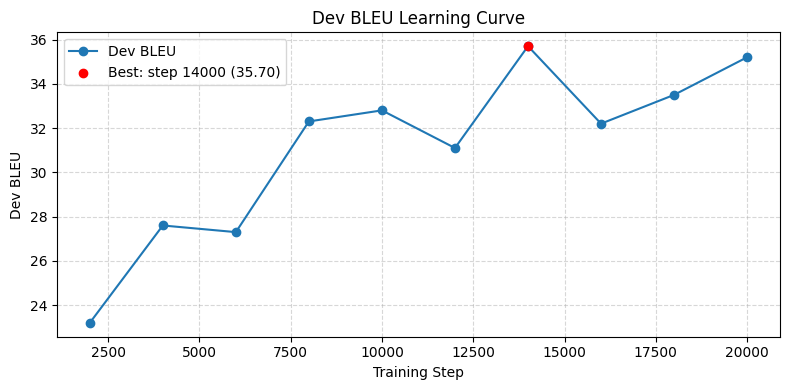

In [13]:
import os
import subprocess
from pathlib import Path
import matplotlib.pyplot as plt

# 2,000ステップ刻みで評価（1,000ステップ刻みにしたい場合は range(1000, 20001, 1000) に変更）
steps = list(range(2000, 20001, 2000))
results = []

for step in steps:
    model_dir = Path(f"tanaka/run/model/step_{step}")
    if not model_dir.exists():
        print(f"step {step}: チェックポイントが見つからないためスキップします ({model_dir})")
        continue
    pred_path = Path(f"pred_step_{step}.txt")
    subprocess.run(
        [
            "eole", "predict",
            "--model_path", str(model_dir),
            "--src", "small_parallel_enja/dev.en",
            "--output", str(pred_path),
            "--gpu_ranks", "0",
        ],
        check=True,
    )
    with pred_path.open("r", encoding="utf-8") as f:
        bleu_out = subprocess.run(
            ["sacrebleu", "-b", "small_parallel_enja/dev.ja"],
            stdin=f,
            capture_output=True,
            text=True,
            check=True,
        )
    score = float(bleu_out.stdout.strip())
    results.append((step, score))
    print(f"step {step:5d}: Dev BLEU = {score:.2f}")

if not results:
    raise RuntimeError("評価可能なチェックポイントが見つかりませんでした。先に学習セルを実行してください。")

best_step, best_bleu = max(results, key=lambda x: x[1])
os.environ["BEST_STEP"] = str(best_step)
print(f"\n最良モデル: step_{best_step} (Dev BLEU = {best_bleu:.2f})")

eval_steps, eval_scores = zip(*results)
plt.figure(figsize=(8, 4))
plt.plot(eval_steps, eval_scores, marker="o", label="Dev BLEU")
plt.scatter([best_step], [best_bleu], color="red", zorder=5, label=f"Best: step {best_step} ({best_bleu:.2f})")
plt.xlabel("Training Step")
plt.ylabel("Dev BLEU")
plt.title("Dev BLEU Learning Curve")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
!echo "Best step: ${BEST_STEP}"
!eole predict --model_path "tanaka/run/model/step_${BEST_STEP}" --src small_parallel_enja/test.en --output pred.txt --gpu_ranks 0
!sacrebleu small_parallel_enja/test.ja < pred.txt

Best step: 14000
[2026-11-19 02:47:09,588 INFO] Init single process mode
[2026-11-19 02:47:09,589 INFO] Loading metadata from tanaka/run/model/step_14000
[2026-11-19 02:47:09,598 INFO] Building model...
[2026-11-19 02:47:09,714 INFO] Loading data into the model
[2026-11-19 02:47:09,957 INFO] Transforms applied: []
[2026-11-19 02:47:09,959 INFO] Build and loading model took 0.37 sec.
[2026-11-19 02:47:10,051 INFO] Inference runtime: torch=2.14.1+cu130, CUDA build=13.0, device=cuda:0, dtype=torch.float32
[2026-11-19 02:47:10,051 INFO] Inference compile: enabled=False, mode=2, layers path=eager, CUDA graphs requested=False; capture not verified
[2026-11-19 02:47:10,051 INFO] Inference speculation: enabled=False, drafts=0, verifier=unused
[2026-11-19 02:47:10,051 INFO] Inference attention: FlashAttention KV-cache selected=False, layers=0, MTP layers selected=0, flash-attn=unavailable, provider=unavailable; other attention calls use PyTorch SDPA/manual attention (SDPA kernel chosen at runti

### 結果の確認と保存

テストデータの翻訳結果を `pandas.DataFrame` にまとめ、文単位の BLEU スコア (`sacrebleu.sentence_bleu`) を計算して翻訳の傾向を確認します。先頭10文に加えて、文BLEUが低いワースト10文や未知語 (`<unk>`) の出現率も確認できます（生のタブ区切りで全件見たい場合は `!paste pred.txt small_parallel_enja/test.{ja,en}` も使えます）。
結果をファイルに保存する場合は `files.download` というメソッドを呼びます。
出力されていない結果は24時間で消えるので、ご注意ください。

In [15]:
from pathlib import Path
import pandas as pd
from IPython.display import display

try:
    import sacrebleu
except ImportError:
    import subprocess
    import sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu"], check=True)
    import sacrebleu

src_lines = Path("small_parallel_enja/test.en").read_text(encoding="utf-8").splitlines()
ref_lines = Path("small_parallel_enja/test.ja").read_text(encoding="utf-8").splitlines()
pred_lines = Path("pred.txt").read_text(encoding="utf-8").splitlines()

assert len(src_lines) == len(ref_lines) == len(pred_lines), (
    f"行数が一致しません: src={len(src_lines)}, ref={len(ref_lines)}, pred={len(pred_lines)}"
)

sent_bleus = [
    round(sacrebleu.sentence_bleu(pred, [ref]).score, 2)
    for pred, ref in zip(pred_lines, ref_lines)
]

df = pd.DataFrame({
    "原文 (en)": src_lines,
    "参照訳 (ja)": ref_lines,
    "システム訳 (pred)": pred_lines,
    "文BLEU": sent_bleus,
})

# <unk> の出現率を集計
unk_sent_count = sum("<unk>" in line.split() for line in pred_lines)
all_tokens = [tok for line in pred_lines for tok in line.split()]
unk_token_count = sum(tok == "<unk>" for tok in all_tokens)
print(f"テスト文数: {len(df)}")
print(f"<unk> を含む文の割合: {unk_sent_count}/{len(df)} ({unk_sent_count / len(df):.1%})")
print(f"<unk> トークンの割合: {unk_token_count}/{len(all_tokens)} ({unk_token_count / max(len(all_tokens), 1):.2%})")

pd.set_option("display.max_colwidth", 80)

print("\n=== 先頭 10 文の翻訳結果 ===")
display(df.head(10))

print("\n=== 文BLEU が低いワースト 10 文 ===")
display(df.sort_values("文BLEU", ascending=True).head(10))

テスト文数: 500
<unk> を含む文の割合: 78/500 (15.6%)
<unk> トークンの割合: 79/5568 (1.42%)

=== 先頭 10 文の翻訳結果 ===


,原文 (en),参照訳 (ja),システム訳 (pred),文BLEU
0,they finally acknowledged it as true .,彼 ら は つい に それ が 真実 だ と 認め た 。,彼 ら は ついに それ を 真実 だ 。,15.56
1,he didn 't care for swimming .,彼 は 水泳 が 得意 で は な かっ た 。,彼 は 泳ぎ が 好き で は な かっ た 。,53.48
2,he is no less kind than his sister .,彼 は お 姉 さん に 劣 ら ず 親切 だ 。,彼 は 姉 ほど 親切 で は な い 。,8.64
3,you must be back before ten .,１０ 時 前 に 戻 ら な けれ ば な ら な い 。,１０ 時 前 に 帰 ら な けれ ば な ら な い 。,78.25
4,break a leg .,成功 を 祈 る わ 。,<unk> を 割 っ て お き なさ い 。,4.03
5,she lives next door to us .,彼女 は 私 たち の 隣 の 家 に す ん で い る 。,彼女 は 私 たち の 隣 に 住 ん で い る 。,58.74
6,i 'm about to tell you the answer .,あなた に 返事 を し よ う と し て い る ところ で す 。,あなた に その 返事 を お 話 し ま す 。,8.56
7,i 'm a person who lives for the moment .,私 は 刹那 的 な 生き 方 を し て い る 人間 で す 。,私 は <unk> に 住 ん で い る 人 で す 。,13.45
8,we have this game on ice .,この 試合 は いただ き だ 。,この 試合 に は 合 う 。,15.62
9,will you give me your reasons for doing this ?,こんな こと を し た 理由 を 言 い な さ い 。,これ を 作 っ て くれ ま せ ん か 。,3.72



=== 文BLEU が低いワースト 10 文 ===


,原文 (en),参照訳 (ja),システム訳 (pred),文BLEU
366,give me the details of it .,その 内訳 は ？,<unk> を くださ い 。,0.00
311,i am as much in the wrong as you are about not writing before this .,ご 無 沙汰 は お 互い さま で す 。,私 は この 前 に 書 く 前 に あなた は 大変 間違 っ て い る 。,2.55
326,can you fix him up for the night ?,今晩 泊め て くれ な い か な 。,彼 を 夜 に <unk> る こと が でき ま す か 。,3.13
168,thank you very much for the wonderful dinner last night .,昨日 は 素晴らし い 夕食 に ご 招待 し て もら っ て 、 ありがとう 。,昨夜 お <unk> を いただ き ありがとう ござ い ま す 。,3.24
448,don 't give in .,負け る な 。,<unk> を 入れ て は いけ ま せ ん 。,3.39
15,at the end of a working day everybody is in a hurry to get home .,一 日 の 仕事 が 終わ る と 皆 家路 を 急 ぐ 。,働 く ため に 働 く ため に 、 急 い だ 。,3.40
410,i will make certain of the situation .,その 状況 を 確かめ て お き ま しょ う 。,私 は どう し て も <unk> を する つもり で す 。,3.46
434,it 's touch and go .,どちら に 転 ぶ か 、 微妙 な ところ で す 。,それ は 触れ な い か 行 っ て しま っ て い る 。,3.46
118,you have no obligation to help us .,あなた は 我々 を 援助 する 必要 は な い 。,私 たち を 助け て くれ る こと は あ り ま せ ん 。,3.46
493,may i have a road map ?,道路 地図 を 下さ い 。,お 風呂 に 入 っ て も い い で す か 。,3.67


In [16]:
import sys
if "google.colab" in sys.modules:
    from google.colab import files
    files.download("pred.txt")

---

## 付録：書籍の OpenNMT-py (v3.5.1) とのコマンド・設定ファイルの対応

書籍の第 4 章 4-4「演習：機械翻訳」では OpenNMT-py (v3.5.1) を使って説明していますが、開発終了に伴い本ノートブックでは後継の **Eole** を使用しています。書籍の記述や旧 OpenNMT-py 版ノートブック ([`misc/ch4_opennmt.ipynb`](https://github.com/mamorlis/nlpbook/blob/main/misc/ch4_opennmt.ipynb)) と本ノートブックの対応関係は次のとおりです。

### 1. コマンドとチェックポイント形式の対応

| 工程 | OpenNMT-py (v3.5.1) | Eole (v0.6.4) | 主な違い |
| --- | --- | --- | --- |
| 語彙構築 | `onmt_build_vocab -config tanaka-enja.yaml -n_sample 10000` | `eole build_vocab -c tanaka-enja.yaml -n_sample 10000` | サブコマンド形式になり、設定ファイル指定が `-config` から `-c`（または `--config`）に変更 |
| モデル訓練 | `onmt_train -config tanaka-enja.yaml` | `eole train -c tanaka-enja.yaml` | 同上 |
| 翻訳（デコード） | `onmt_translate --model tanaka/run/model_step_20000.pt --src ... --output pred.txt` | `eole predict --model_path tanaka/run/model/step_20000 --src ... --output pred.txt --gpu_ranks 0` | モデル指定が `--model` から `--model_path` になり、GPU 推論時は `--gpu_ranks 0` を明示指定 |
| チェックポイント形式 | 単一ファイル（例: `tanaka/run/model_step_20000.pt`） | ディレクトリ（例: `tanaka/run/model/step_20000/`） | Eole は重み・語彙・設定をディレクトリ単位で保存（親ディレクトリ指定で最新モデルを使用可） |

### 2. 設定 YAML とオプションの違い

OpenNMT-py では学習・保存設定やモデル設定を YAML のトップレベルにフラットに記述していましたが、Eole では **`model:` セクション**と **`training:` セクション**に構造化します。

- **データの指定 (`data:`)**: OpenNMT-py の `corpus_1` にあった `weight: 1` は Eole の最小設定では省略できます（`save_data`, `src_vocab`, `tgt_vocab`, `overwrite` は共通でトップレベルに記述）。
- **モデル設定 (`model:`)**: OpenNMT-py ではデフォルトで RNN (LSTM) が使われ、Transformer を使う場合もトップレベルに `encoder_type: transformer` 等を書いていましたが、Eole では `model:` セクション配下に `architecture: rnn` や `architecture: transformer`（および `layers`, `heads`, `hidden_size` 等）をまとめて記述します。
- **学習・保存設定 (`training:`)**:
  - OpenNMT-py でトップレベルに書いていた `world_size`, `gpu_ranks: [0]`, `save_checkpoint_steps`, `train_steps`, `valid_steps` などは、Eole では `training:` セクション配下に配置します。
  - チェックポイント保存先のキー名は、OpenNMT-py の `save_model: ./tanaka/run/model` から Eole では `training.model_path: ./tanaka/run/model` に変わります。
- **GPU 指定の違い**: 訓練時はどちらも設定 YAML 内で `world_size: 1`・`gpu_ranks: [0]` を指定します。デコード時は、OpenNMT-py の `onmt_translate` がオプションなしでも実行できる（GPU 利用時は `-gpu 0` 等）のに対し、Eole の `eole predict` ではコマンドライン引数として `--gpu_ranks 0` を指定します。